# Solution summary

This notebook uses weather data from the Norwegian Meteorological Institute for station SN17850 in Ås. It downloads daily temperature and precipitation for 2025, compares the year with a 1925 record, detects heatwaves using the 5-day threshold, and calculates a 7-day moving average. The results are presented as plots and summary statistics to match the deliverable requirements.
GitHub Repo - [INF201_deliverable_1](https://github.com/SheathAndWhitley/INF201_deliverable_1)

## Imports

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import statistics as st
import os


## Task 1

Task 1: This section requests daily mean air temperature for all of 2025, plots the annual seasonal pattern, and prints the year’s summary statistics. The result shows the expected temperature cycle across the year, with the minimum, maximum, median, and mean values giving a compact view of the climate in Ås for 2025.

In [22]:

client_id = os.environ.get('client_id')

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert frost_response.status_code == 200

AssertionError: 

In [27]:
temp_task1 = []
time_task1 = []

for entry in frost_data_task1['data']:
    
    temperature = entry['observations'][0]['value']
    date = pd.to_datetime(entry['referenceTime'])

    temp_task1.append(temperature)
    time_task1.append(date)

KeyError: 'data'

### Temp. Plot

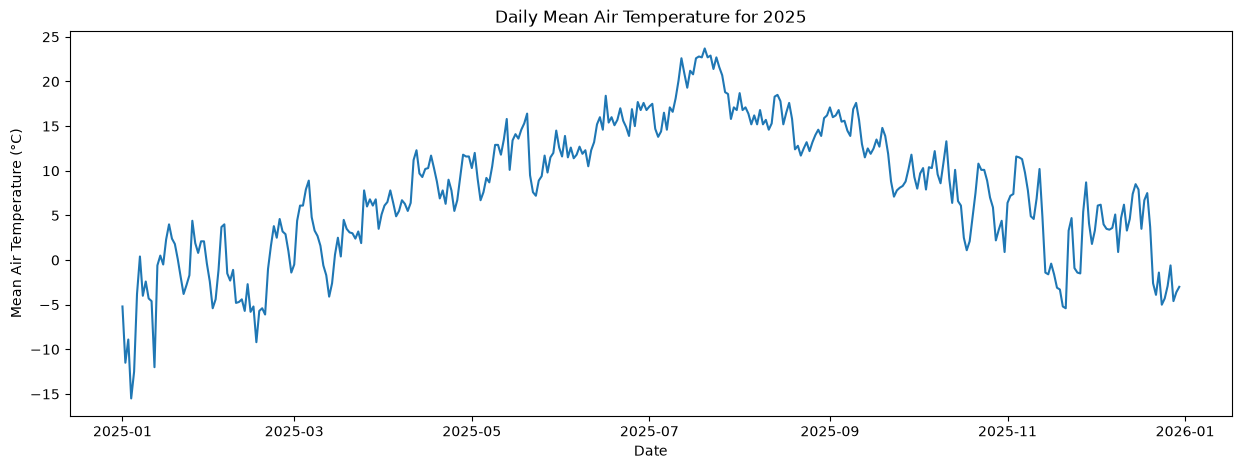

In [ ]:
plt.figure(figsize=(15, 5))
plt.title('Daily Mean Air Temperature for 2025')
plt.xlabel('Date')
plt.ylabel('Mean Air Temperature (°C)')
plt.plot(time_task1, temp_task1)
plt.show()

### Summary Table

In [ ]:
mean_temp_task1 = sum(temp_task1) / len(temp_task1)
max_temp_task1  = max(temp_task1)
min_temp_task1  = min(temp_task1)
median_temp_task1 = st.median(temp_task1)

print(f"Summary Statistics for Daily Mean Air Temperature in 2025:")
print(f"Mean: {mean_temp_task1:8.2f} °C")
print(f"Max: {max_temp_task1:8.2f} °C")
print(f"Min: {min_temp_task1:8.2f} °C")

Summary Statistics for Daily Mean Air Temperature in 2025:
Mean:     7.90 °C
Max:    23.70 °C
Min:   -15.50 °C


## Task 2

Task 2: This section downloads daily precipitation for the same period and combines it with the temperature series in a single dual-axis plot. The result makes it easier to see how precipitation events overlap with warm and cold periods, highlighting that temperature and rainfall do not necessarily follow the same seasonal pattern.

In [ ]:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert frost_response.status_code == 200

frost_data_task2 = frost_response.json()

{'sourceId': 'SN17850:0',
 'referenceTime': '2025-01-01T00:00:00.000Z',
 'observations': [{'elementId': 'sum(precipitation_amount P1D)',
   'value': 5.4,
   'unit': 'mm',
   'timeOffset': 'PT18H',
   'timeResolution': 'P1D',
   'timeSeriesId': 0,
   'performanceCategory': 'C',
   'exposureCategory': '2'},
  {'elementId': 'sum(precipitation_amount P1D)',
   'value': 6.6,
   'unit': 'mm',
   'timeOffset': 'PT6H',
   'timeResolution': 'P1D',
   'timeSeriesId': 0,
   'performanceCategory': 'C',
   'exposureCategory': '2',
   'qualityCode': 0}]}

In [ ]:
time_task2 = []
precipitation_task2 = []
for entry in frost_data_task2['data']:
    
    precip = entry['observations'][1]['value']
    date = pd.to_datetime(entry['referenceTime'])

    precipitation_task2.append(precip)
    time_task2.append(date)

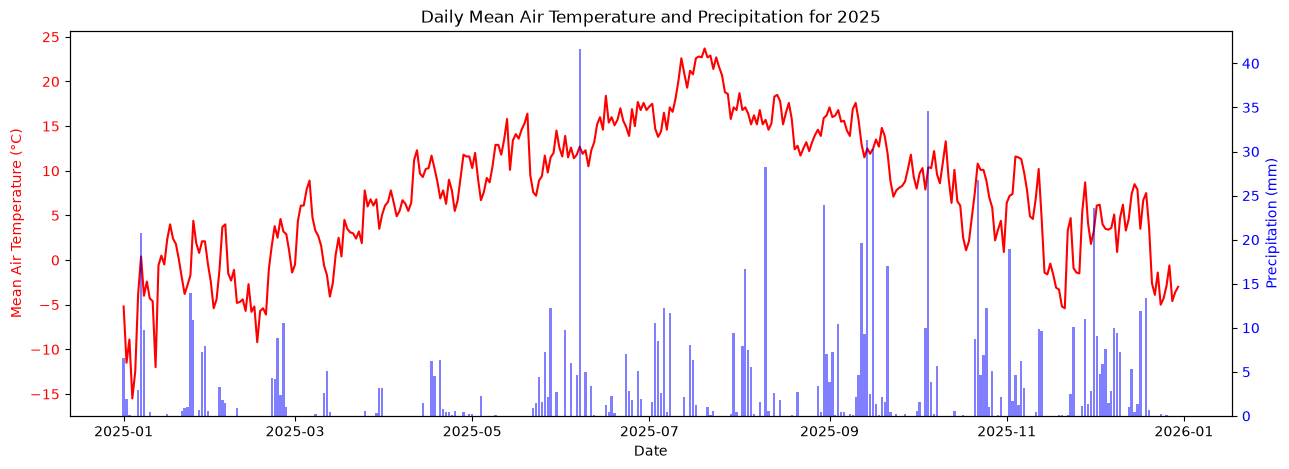

In [ ]:

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.set_title('Daily Mean Air Temperature and Precipitation for 2025')
ax1.set_xlabel('Date')

ax1.set_ylabel('Mean Air Temperature (°C)', color='red')
ax1.plot(time_task1, temp_task1, color='red', label='Mean Air Temperature')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.set_ylabel('Precipitation (mm)', color='blue')
ax2.bar(time_task2, precipitation_task2, color='blue', alpha=0.5, label='Precipitation')
ax2.tick_params(axis='y', labelcolor='blue')

plt.show()



## Task 3

Task 3: This section compares the 2025 temperature series with a 1925 dataset on the same plot and prints summary statistics side by side. The result illustrates how the climate has changed over time, showing the two years in direct comparison and making differences in average level and variability easier to interpret.

In [ ]:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '1925-01-01/1925-12-31',
}

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert frost_response.status_code == 200

frost_data_task3 = frost_response.json()

{'sourceId': 'SN17850:0',
 'referenceTime': '1925-01-01T00:00:00.000Z',
 'observations': [{'elementId': 'mean(air_temperature P1D)',
   'value': 1.3,
   'unit': 'degC',
   'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2},
   'timeOffset': 'PT0H',
   'timeResolution': 'P1D',
   'timeSeriesId': 0,
   'performanceCategory': 'C',
   'exposureCategory': '1',
   'qualityCode': 2}]}

In [ ]:
temp_task3 = []
time_task3 = []

for entry in frost_data_task3['data']:
    temperature = entry['observations'][0]['value']
    date = pd.to_datetime(entry['referenceTime'])

    temp_task3.append(temperature)
    time_task3.append(date)

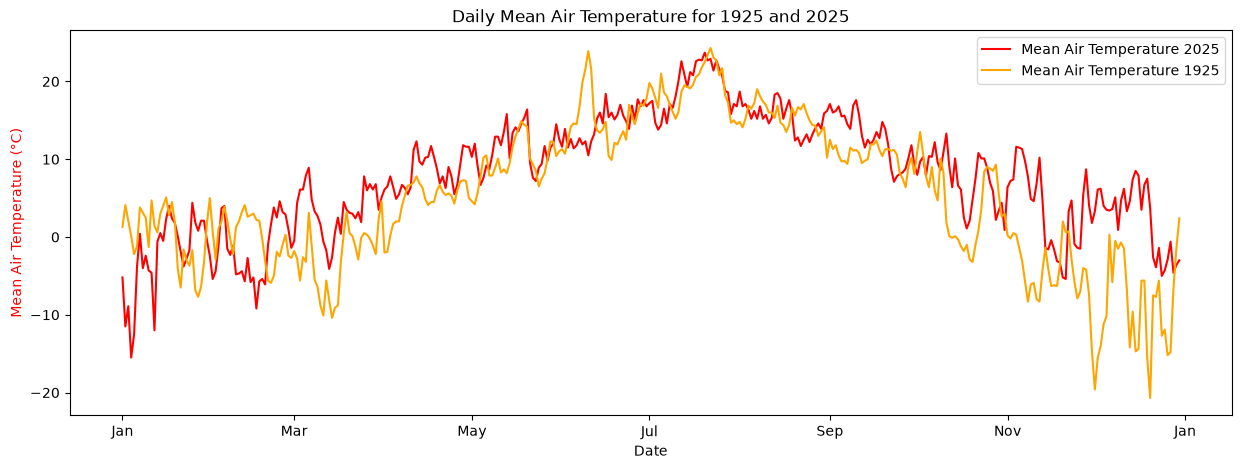

In [ ]:
fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.set_title('Daily Mean Air Temperature for 1925 and 2025')
ax1.set_xlabel('Date')
ax1.set_ylabel('Mean Air Temperature (°C)', color='red')
ax1.plot(time_task1, temp_task1, color='red', label='Mean Air Temperature 2025')
ax1.plot(time_task1, temp_task3, color='orange',label='Mean Air Temperature 1925')

ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax1.legend()

plt.show()


In [ ]:
mean_temp_task3 = sum(temp_task3) / len(temp_task3)
max_temp_task3  = max(temp_task3)
min_temp_task3  = min(temp_task3)
median_temp_task3 = st.median(temp_task3)

print("Summary Statistics for Daily Mean Air Temperature in 1925 vs 2025:")
print(f"Mean 1925:   {mean_temp_task3:7.2f} °C  |  Mean 2025:   {mean_temp_task1:7.2f} °C")
print(f"Max 1925:    {max_temp_task3:7.2f} °C  |  Max 2025:    {max_temp_task1:7.2f} °C")
print(f"Min 1925:    {min_temp_task3:7.2f} °C  |  Min 2025:    {min_temp_task1:7.2f} °C")
print(f"Median 1925: {median_temp_task3:7.2f} °C  |  Median 2025: {median_temp_task1:7.2f} °C")

Summary Statistics for Daily Mean Air Temperature in 1925 vs 2025:
Mean 1925:      5.31 °C  |  Mean 2025:      7.90 °C
Max 1925:      24.30 °C  |  Max 2025:      23.70 °C
Min 1925:     -20.70 °C  |  Min 2025:     -15.50 °C
Median 1925:    5.30 °C  |  Median 2025:    8.40 °C


## Task 4

Task 4: This section defines a heatwave as five or more consecutive days with daily maximum temperature at or above 27 °C, then writes the detected periods to a YAML file. The result is a structured summary of the heatwave dates for the selected station and year, which makes it possible to identify unusually warm periods in a reproducible way.

In [ ]:
year = 2025
station = 'SN17850'

def find_heatwaves(year, station):
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        f'sources': f'{station}',
        'elements': 'max(air_temperature P1D)',
        f'referencetime': f'{year}-01-01/{year}-12-31',
    }

    frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
    assert frost_response.status_code == 200

    frost_data_task4 = frost_response.json()

    temp_task4 = []
    time_task4 = []
    for entry in frost_data_task4['data']:
        temperature = entry['observations'][0]['value']
        date = pd.to_datetime(entry['referenceTime'])

        temp_task4.append(temperature)
        time_task4.append(date)

    counter = 0
    heatwaves = []
    start_date = None
    end_date = None

    for temp, time in zip(temp_task4, time_task4):

        if temp >= 27:
            if counter == 0:
                start_date = time
            counter += 1
            end_date = time
        else:
            if counter >= 5:
                heatwaves.append({'start_date': start_date, 'end_date': end_date})
            counter = 0

    if counter >= 5:
        heatwaves.append({'start_date': start_date, 'end_date': end_date})
    
    return heatwaves
        
        
info = (find_heatwaves(year, station))

In [ ]:
with open('heatwave_summary.yml', 'w') as file:
    for i in range(len(info)):
        file.write(f"date: \n - {info[i]['start_date']} -> {info[i]['end_date']}\n")

    file.write(f"Station ID: {station}\n")
    file.write(f"Station Name: \n")
    file.write(f"Year: {year}\n")


## Task 5

Task 5: This final section calculates a 7-day moving average from the 2025 temperature data and overlays it on the original daily values. The result smooths short-term fluctuations, making the underlying trend more visible and helping to show periods of sustained warming or cooling that are less obvious in the raw daily series.

In [ ]:
rolling_average = []
window_size = 7

def calculate_rolling_average(window_size, data):
    for i in range(len(data)):
        if i < window_size - 1:
            rolling_average.append(None)
        else:
            seven_day_window = data[i - window_size + 1:i + 1]
            average = sum(seven_day_window) / window_size
            rolling_average.append(average)

    return rolling_average

calculate_rolling_average(7, temp_task1)

[None,
 None,
 None,
 None,
 None,
 None,
 -8.142857142857142,
 -7.971428571428571,
 -6.671428571428572,
 -6.014285714285714,
 -4.457142857142856,
 -4.385714285714285,
 -3.928571428571428,
 -3.914285714285714,
 -3.414285714285714,
 -2.742857142857143,
 -1.5571428571428574,
 -0.5571428571428572,
 1.4142857142857141,
 1.5142857142857142,
 1.1714285714285713,
 0.7000000000000001,
 -0.02857142857142845,
 -0.8428571428571427,
 -0.557142857142857,
 -0.5428571428571428,
 -0.4428571428571427,
 0.1285714285714287,
 0.9714285714285715,
 1.3142857142857145,
 1.2142857142857142,
 -0.18571428571428575,
 -1.0857142857142859,
 -1.3571428571428572,
 -1.1285714285714286,
 -0.8571428571428573,
 -1.0142857142857145,
 -1.0,
 -0.38571428571428573,
 -0.4428571428571429,
 -0.9571428571428571,
 -2.1142857142857143,
 -3.5,
 -3.6714285714285713,
 -4.171428571428572,
 -4.757142857142857,
 -5.385714285714286,
 -5.528571428571429,
 -5.671428571428572,
 -5.728571428571429,
 -5.485714285714286,
 -4.428571428571429,


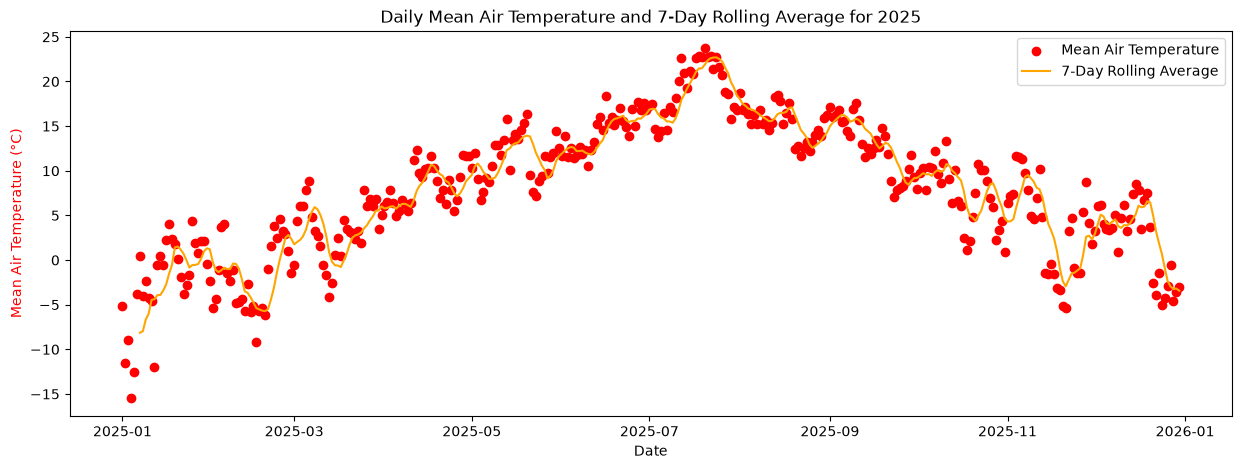

In [19]:
fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.set_title('Daily Mean Air Temperature and 7-Day Rolling Average for 2025')
ax1.set_xlabel('Date')
ax1.set_ylabel('Mean Air Temperature (°C)', color='red')
ax1.scatter(time_task1, temp_task1, color='red', label='Mean Air Temperature')
ax1.plot(time_task1, rolling_average, color='orange', label='7-Day Rolling Average')
ax1.legend()

plt.show()